---
# **Cuaderno 2:**  Analisis de datos de ICGC
---
* Author: Melissa Ormeño; Alexis Salas
* Laboratory: Cancer Molecular Dynamics
* Date: Agosto 2025

**Aims:**

* Analiza los datos obtenidos al filtrar por gen un archivo de mutaciones de la base de datos del ICGC

### Librerias

In [18]:
import pandas as pd
import requests
import re
import matplotlib.pyplot as plt

### Cargar archivo de mutaciones

El archivo proviene del cuaderno 01_Cancer_mutations

In [11]:
#Nombre grupo de genes
grupo = "tgfb"
#Ruta 
ruta = "../data/Cancer/mut_cancer_{0}.csv".format(grupo)
#Cargar archivo
df = pd.read_csv(ruta)
df = df.drop_duplicates()
#Datos
print(f"tamaño: \n{df.shape}")
print(f"valores nulos: \n{df.isnull().sum()}")


df.head(2)

tamaño: 
(33954, 8)
valores nulos: 
icgc_donor_id              0
uniprot_id                 0
gen_name                   0
aa_mutation            27339
tipo_cancer                0
transcript_affected        0
verification_status        0
consequence_type           0
dtype: int64


,icgc_donor_id,uniprot_id,gen_name,aa_mutation,tipo_cancer,transcript_affected,verification_status,consequence_type
0,DO37659,Q13873,BMPR2,NaN,Piel,ENST00000374574,not tested,3_prime_UTR_variant
1,DO37659,Q13873,BMPR2,P978P,Piel,ENST00000374580,not tested,synonymous_variant


## 1. Procesar archivo de mutaciones


In [12]:
df_cancer = df.dropna()
print(f"Tamaño: {df_cancer.shape}")
print(f"Número de pacientes: {df_cancer['icgc_donor_id'].nunique()}")
print(f"Número de genes: {df_cancer['gen_name'].nunique()}")

Tamaño: (6615, 8)
Número de pacientes: 1297
Número de genes: 12


In [13]:
#Crea un data frame donde solo esten los datos que han sido verificados y que no esten testeados
df_verificado = df_cancer.loc[(df_cancer['verification_status'] == 'tested and verified') | (df_cancer['verification_status'] == 'not tested')]
print(f"Verificacion (df_cancer): {df_cancer['verification_status'].unique()}")
print(f"Verificacion (df_verificado): {df_verificado['verification_status'].unique()}")
print(f"Tamaño: {df_verificado.shape}")

Verificacion (df_cancer): ['not tested' 'tested and verified' 'tested and verified to be false']
Verificacion (df_verificado): ['not tested' 'tested and verified']
Tamaño: (6609, 8)


In [14]:
# elimina las mutaciones synonymous (silenciosas) 
df_consequence=df_verificado[df_verificado['consequence_type'] != 'synonymous_variant'].reset_index(drop=True)
print(f"Tamaño: {df_consequence.shape}")
print(f"Tipos de mutación: \n{df_consequence['consequence_type'].unique()}")


Tamaño: (5245, 8)
Tipos de mutación: 
['missense_variant' 'stop_gained' 'frameshift_variant' 'inframe_deletion'
 'stop_lost' 'stop_retained_variant' 'start_lost'
 'disruptive_inframe_insertion']


In [15]:
#Numero de mutaciones unicas y pacientes 
print(f"Número de mutaciones: {df_consequence['aa_mutation'].nunique()}")
print(f"Número de pacientes: {df_consequence['icgc_donor_id'].nunique()}")

Número de mutaciones: 2762
Número de pacientes: 1070


## 2. Clasificación de mutaciones por Dominio

In [16]:
# Lista de uniprot ID

#uniprot_ids = ["Q13873","P37173","Q04771"]

uniprot_ids = df_consequence["uniprot_id"].unique()

dominios_interes = ["kinase", "GS", "Extracellular", "transmembrane"]

def get_features(uniprot_ids):

    features_dict = {}
    
    for uniprot_id in uniprot_ids:
        url = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}"
        response = requests.get(url)
    
        if response.status_code != 200:
            print(f"Error al obtener {uniprot_id}: {response.status_code}")
            continue
    
        json_data = response.json()
        gen_name = (json_data.get("genes",[{}])[0].get("geneName",{}) or {}).get("value", uniprot_id)
        features = json_data.get("features", [])

        features_dict[gen_name] = []
    
        for feature in features:
            ftype = feature.get("type")
            loc = feature.get("location", {})
            start = (loc.get("start") or {}).get("value")
            end = (loc.get("end") or {}).get("value")
            description = feature.get("description", "")
    
            if not (ftype and start and end):
                continue
    
            motif_name = ftype if not description else f"{ftype}_{description}"
            motif_name_l = motif_name.lower()
    
            # 1) Incluir (dominios_interes)
            if not any(keyword.lower() in motif_name_l for keyword in dominios_interes):
                continue
    
            # 2) Excluir 
            if "mutagenesis" in motif_name_l:
                continue
    
            # Nombre de dominio
            if "kinase" in motif_name_l or "protein kinase" in motif_name_l:
                categoria = "Kinasa"
            elif "gs" in motif_name_l or "fkbp1a-binding" in motif_name_l:
                categoria = "GS"
            elif "extracellular" in motif_name_l or "propeptide" in motif_name_l or "ectodominio" in motif_name_l:
                categoria = "Ectodominio"
            elif "transmembrane" in motif_name_l:
                categoria = "Transmembrana"
            elif "signal" in motif_name_l:
                categoria = "Signal"
            else:
                categoria = "Otro"
    
            # 3) Guardar 
            features_dict[gen_name].append({
                #"uniprot_id": uniprot_id,
                #"gen_name": gen_name,
                #"Motivo/dominio": motif_name,
                "Dominio": categoria,
                "Start": int(start),
                "End": int(end)
                
            })

    return features_dict

data = get_features(uniprot_ids)

def clasificar_mutacion(row):
   
    gene = row['gen_name']
    mutation = row['aa_mutation']

    if gene in data:

        position = int(''.join(filter(str.isdigit, mutation)))
        
        # Recorrer la lista de dominios de ese gen
        for dominio in data[gene]:
            start = dominio["Start"]
            end = dominio["End"]
            nombre = dominio["Dominio"]
            
            if start <= position <= end:
            
                return pd.Series([nombre, f"{start}-{end}"])  # Dominio y rango

    return pd.Series(["Otro", None]) 

df_consequence[['Dominio', "Rango"]] = df_consequence.apply(clasificar_mutacion, axis=1)
df_consequence

,icgc_donor_id,uniprot_id,gen_name,aa_mutation,tipo_cancer,transcript_affected,verification_status,consequence_type,Dominio,Rango
0,DO37571,Q13873,BMPR2,P516Q,Piel,ENST00000374580,not tested,missense_variant,Otro,None
1,DO37571,Q13873,BMPR2,P516Q,Piel,ENST00000374574,not tested,missense_variant,Otro,None
2,DO37551,Q13873,BMPR2,W484L,Piel,ENST00000374574,not tested,missense_variant,Kinasa,203-504
3,DO37551,Q13873,BMPR2,W484L,Piel,ENST00000374580,not tested,missense_variant,Kinasa,203-504
4,DO37827,Q13873,BMPR2,S233F,Piel,ENST00000374574,not tested,missense_variant,Kinasa,203-504
...,...,...,...,...,...,...,...,...,...,...
5240,DO555,P37173,TGFBR2,Q29E,Vejiga,ENST00000295754,not tested,missense_variant,Ectodominio,23-166
5241,DO512,P37173,TGFBR2,M425I,Vejiga,ENST00000295754,not tested,missense_variant,Kinasa,244-544
5242,DO512,P37173,TGFBR2,M450I,Vejiga,ENST00000359013,not tested,missense_variant,Kinasa,244-544
5243,DO785,P37173,TGFBR2,A261R?,Vejiga,ENST00000295754,not tested,frameshift_variant,Kinasa,244-544


## 3. Visualización de resultados

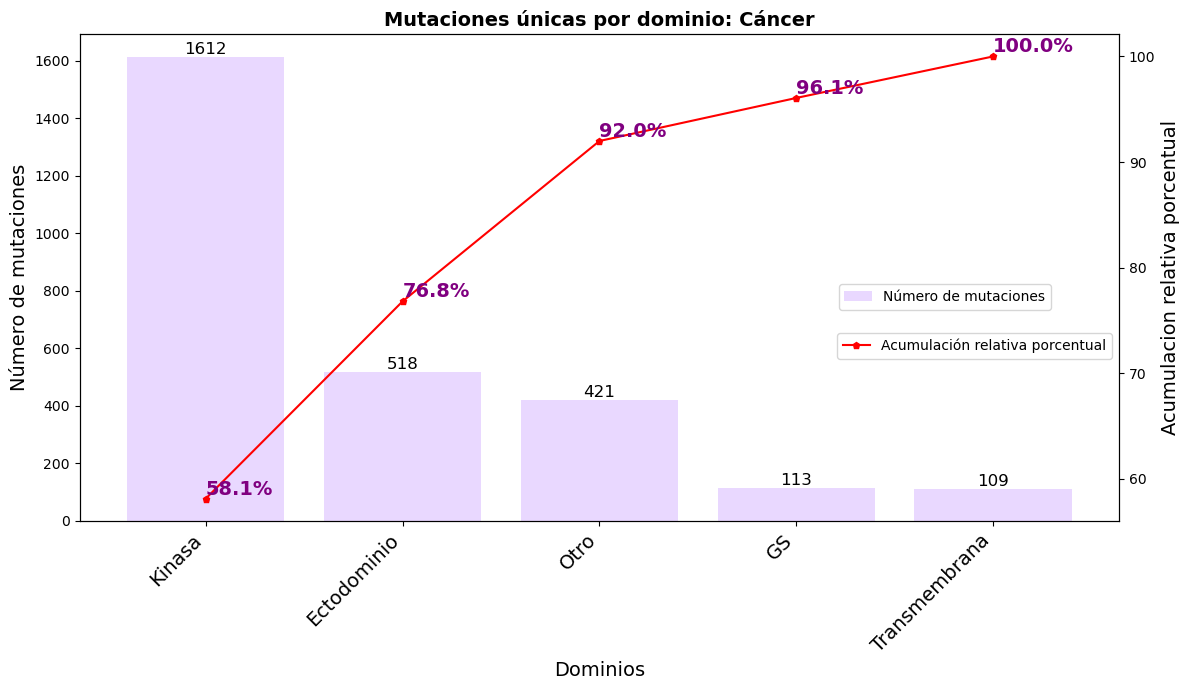

In [28]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "Dominio" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por dominio: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


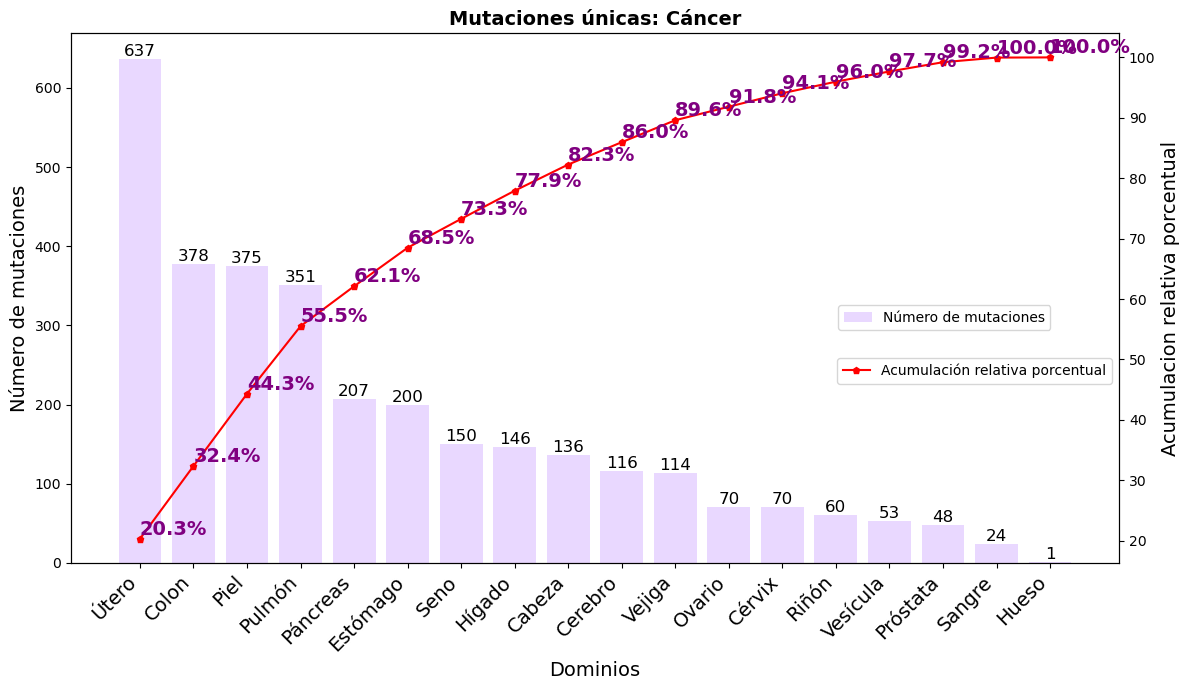

In [29]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "tipo_cancer" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


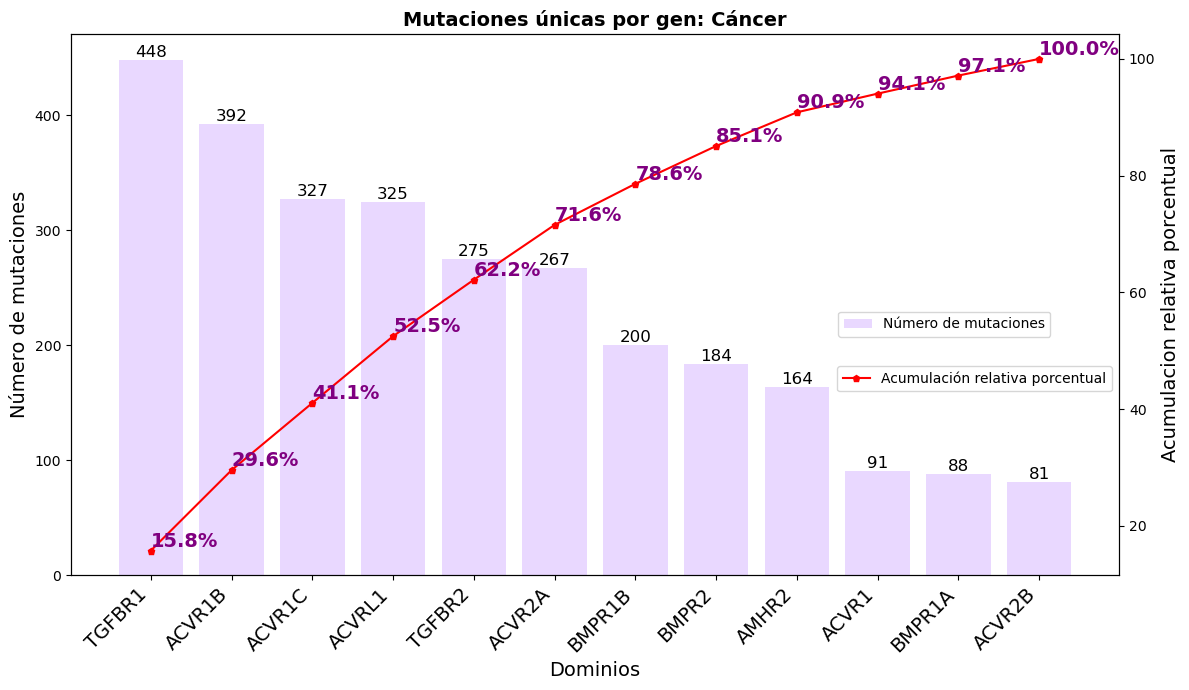

In [30]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "gen_name" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por gen: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


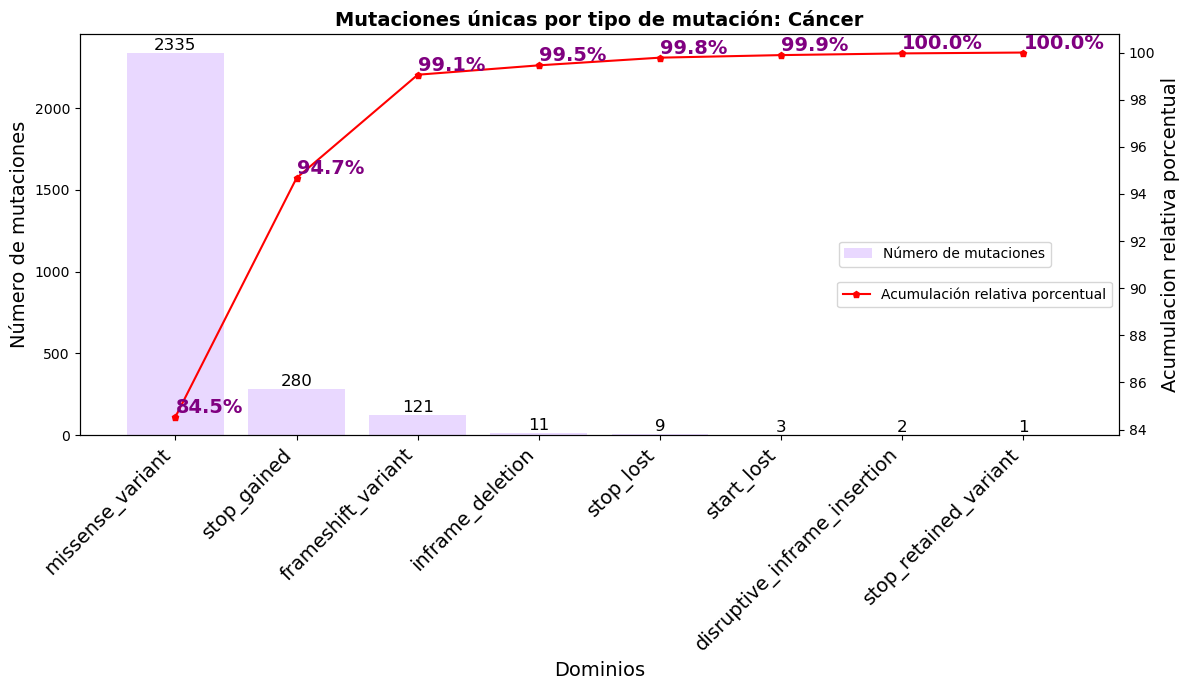

In [32]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "consequence_type" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por tipo de mutación: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()
